In [1]:

%pip install -q -U transformers accelerate sentencepiece


In [2]:

import torch
import transformers
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )


PyTorch: 2.14.1+cu130
Transformers: 5.22.2
Accelerate: 1.15.0
GPU available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3-1.7B"

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("\nModel loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", model.device)
print("Data type:", model.dtype)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading tokenizer...


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (5 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


Model loaded successfully!
Model: Qwen/Qwen3-1.7B
Device: cuda:0
Data type: torch.float16
GPU memory allocated: 3.21 GB


In [4]:
def generate_response(prompt, max_new_tokens=150):
    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )


tests = {
    "English": "Extract the name and amount: Name: Ravi Kumar, Amount: 2500",
    "Hindi": "इस पाठ से नाम और राशि निकालें: नाम: रवि कुमार, राशि: 2500",
    "Kannada": "ಈ ಪಠ್ಯದಿಂದ ಹೆಸರು ಮತ್ತು ಮೊತ್ತವನ್ನು ಹೊರತೆಗೆಯಿರಿ: ಹೆಸರು: ರವಿ ಕುಮಾರ್, ಮೊತ್ತ: 2500"
}

for language, prompt in tests.items():
    print(f"\n{'='*50}")
    print(language)
    print(generate_response(prompt))


English
Name: Ravi Kumar  
Amount: 2500

Hindi
नाम: रवि कुमार  
राशि: 2500

Kannada
ಹೆಸರು: ರವಿ ಕುಮಾರ್  
ಮೊತ್ತ: 2500


In [5]:
from google.colab import drive
drive.mount('/content/drive')

import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/BharatDocAI")

ocr_files = {
    "Tesseract": PROJECT_ROOT / "data/ocr_outputs/phase0_ocr.json",
    "EasyOCR": PROJECT_ROOT / "data/ocr_outputs/easyocr_results.json",
    "PaddleOCR": PROJECT_ROOT / "data/ocr_outputs/paddleocr_results.json"
}

for engine, path in ocr_files.items():
    print(f"\n{'='*60}")
    print(engine)

    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("File found")
        print("Data type:", type(data).__name__)

        if isinstance(data, dict):
            print("Languages:", list(data.keys()))

            for language, content in data.items():
                print(f"\n{language}:")
                print(str(content)[:1000])
    else:
        print("File not found:", path)

Mounted at /content/drive

Tesseract
File found
Data type: dict
Languages: ['english', 'hindi', 'kannada']

english:
INVOICE

Name: Ravi Kumar
Date: 12/08/2026
Invoice No: INV-1045
Address: Bengaluru
Amount: 2500


hindi:
चालान

नाम: रवि कुमार

दिनांक: 42/08/2026
चालान संख्या: ॥00- 045
पता: बेंगलुरु

राशि: 2500


kannada:
ಸರಕುಪಟ್ಟಿ

ಹೆಸರು: ರವಿ ಕುಮಾರ್‌
ದಿನಾಂಕ: 12/08/2026
ಸರಕುಪಟ್ಟಿ ಸಂಖ್ಯೆ: 111-1045
ವಿಳಾಸ: ಬೆಂಗಳೂರು

ಮೊತ್ತ: 2500


EasyOCR
File found
Data type: dict
Languages: ['english', 'hindi', 'kannada']

english:
INVOICE
Name: Ravi Kumar
Date: 12/08/2026
Invoice No: INV-1045
Address: Bengaluru
Amount: 2500

hindi:
चालान
नामः रवि कुमार
दिनांकः १२/०8/२०२६
चालान संख्याः `DD-1०४५
पताः
राशिः २५००
बेंगलुरु

kannada:
ಸರಕುಪಟ್ಟಿ
ಹೆಸರು: ರವಿ ಕುಮಾರ್
ದಿನಾಂಕ: 12 /08 | 2026
ಸರಕುಪಟ್ಟಿ ಸಂಖ್ಯೆ: [LL-1045
ವಿಳಾಸ: ಬೆಂಗಳೂರು
ಮೊತ್ತ: 2500

PaddleOCR
File found
Data type: dict
Languages: ['english', 'hindi']

english:
INVOICE
Name: Ravi Kumar
Date: 12/08/2026
Invoice No: INV-1045
Address: Bengaluru
Amount: 2500


In [6]:
import json
import re
import torch
from pathlib import Path

# Load OCR outputs
ocr_data = {}

for engine, path in ocr_files.items():
    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            ocr_data[engine] = json.load(f)

# Fields required in our extraction schema
FIELDS = [
    "name",
    "date",
    "invoice_number",
    "address",
    "amount"
]

def build_extraction_prompt(language, ocr_text):

    return f"""
You are an information extraction system.

Extract the following fields from the OCR text of an invoice.

Required JSON fields:
- name
- date
- invoice_number
- address
- amount

Rules:
1. Return only valid JSON.
2. Use exactly the five required keys.
3. All values must be strings.
4. If a field is missing or unreadable, return an empty string.
5. Do not invent or guess missing information.
6. Preserve the original meaning and spelling of extracted values.
7. Do not explain your answer.

Document language: {language}

OCR TEXT:
{ocr_text}

Expected JSON format:
{{
    "name": "",
    "date": "",
    "invoice_number": "",
    "address": "",
    "amount": ""
}}
"""

def extract_json(response):

    # Remove possible Markdown code fences
    response = re.sub(
        r"```(?:json)?",
        "",
        response,
        flags=re.IGNORECASE
    ).replace("```", "").strip()

    # Find JSON object
    match = re.search(r"\{.*\}", response, flags=re.DOTALL)

    if not match:
        return None

    try:
        data = json.loads(match.group())

        if not isinstance(data, dict):
            return None

        return {
            field: str(data.get(field, "") or "")
            for field in FIELDS
        }

    except json.JSONDecodeError:
        return None


def run_extraction(language, ocr_text):

    prompt = build_extraction_prompt(language, ocr_text)

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[-1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    parsed = extract_json(response)

    return {
        "raw_response": response,
        "extracted_json": parsed,
        "json_valid": parsed is not None
    }


# Run experiment
zero_shot_results = {}

for engine, language_data in ocr_data.items():

    zero_shot_results[engine] = {}

    for language, ocr_text in language_data.items():

        print(f"\n{'='*60}")
        print(f"Engine: {engine} | Language: {language}")

        result = run_extraction(language, ocr_text)

        zero_shot_results[engine][language] = result

        print("Raw response:")
        print(result["raw_response"])

        print("\nParsed JSON:")
        print(result["extracted_json"])

        print("Valid JSON:", result["json_valid"])


# Save experiment results
OUTPUT_DIR = PROJECT_ROOT / "experiments/baselines"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "qwen3_zero_shot_results.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        zero_shot_results,
        f,
        ensure_ascii=False,
        indent=4
    )

print("\nZero-shot experiment completed.")
print("Saved to:", output_path)


Engine: Tesseract | Language: english
Raw response:
{
    "name": "Ravi Kumar",
    "date": "12/08/2026",
    "invoice_number": "INV-1045",
    "address": "Bengaluru",
    "amount": "2500"
}

Parsed JSON:
{'name': 'Ravi Kumar', 'date': '12/08/2026', 'invoice_number': 'INV-1045', 'address': 'Bengaluru', 'amount': '2500'}
Valid JSON: True

Engine: Tesseract | Language: hindi
Raw response:
{
    "name": "",
    "date": "",
    "invoice_number": "",
    "address": "बेंगलुरु",
    "amount": "2500"
}

Parsed JSON:
{'name': '', 'date': '', 'invoice_number': '', 'address': 'बेंगलुरु', 'amount': '2500'}
Valid JSON: True

Engine: Tesseract | Language: kannada
Raw response:
{
    "name": "",
    "date": "",
    "invoice_number": "",
    "address": "బెంగళూరు",
    "amount": "2500"
}

Parsed JSON:
{'name': '', 'date': '', 'invoice_number': '', 'address': 'బెంగళూరు', 'amount': '2500'}
Valid JSON: True

Engine: EasyOCR | Language: english
Raw response:
{
    "name": "Ravi Kumar",
    "date": "12/08/

In [7]:
import json
from pathlib import Path

GROUND_TRUTH_PATH = (
    PROJECT_ROOT / "data/annotations/phase0_ground_truth.json"
)

with open(GROUND_TRUTH_PATH, "r", encoding="utf-8") as f:
    ground_truth = json.load(f)

print("Ground truth structure:")
print(json.dumps(
    ground_truth,
    ensure_ascii=False,
    indent=4
))

Ground truth structure:
{
    "english": {
        "language": "eng",
        "text": "INVOICE\nName: Ravi Kumar\nDate: 12/08/2026\nInvoice No: INV-1045\nAddress: Bengaluru\nAmount: 2500"
    },
    "hindi": {
        "language": "hin",
        "text": "चालान\nनाम: रवि कुमार\nदिनांक: 12/08/2026\nचालान संख्या: INV-1045\nपता: बेंगलुरु\nराशि: 2500"
    },
    "kannada": {
        "language": "kan",
        "text": "ಸರಕುಪಟ್ಟಿ\nಹೆಸರು: ರವಿ ಕುಮಾರ್\nದಿನಾಂಕ: 12/08/2026\nಸರಕುಪಟ್ಟಿ ಸಂಖ್ಯೆ: INV-1045\nವಿಳಾಸ: ಬೆಂಗಳೂರು\nಮೊತ್ತ: 2500"
    }
}


In [8]:
import json
from pathlib import Path

# Structured ground truth based on phase0_ground_truth.json
structured_ground_truth = {
    "english": {
        "name": "Ravi Kumar",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "Bengaluru",
        "amount": "2500"
    },
    "hindi": {
        "name": "रवि कुमार",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "बेंगलुरु",
        "amount": "2500"
    },
    "kannada": {
        "name": "ರವಿ ಕುಮಾರ್",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "ಬೆಂಗಳೂರು",
        "amount": "2500"
    }
}

ANNOTATION_DIR = PROJECT_ROOT / "data/annotations"
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

structured_gt_path = (
    ANNOTATION_DIR / "structured_ground_truth.json"
)

with open(structured_gt_path, "w", encoding="utf-8") as f:
    json.dump(
        structured_ground_truth,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Structured ground truth created:")
print(json.dumps(
    structured_ground_truth,
    ensure_ascii=False,
    indent=4
))

print("\nSaved to:", structured_gt_path)

Structured ground truth created:
{
    "english": {
        "name": "Ravi Kumar",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "Bengaluru",
        "amount": "2500"
    },
    "hindi": {
        "name": "रवि कुमार",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "बेंगलुरु",
        "amount": "2500"
    },
    "kannada": {
        "name": "ರವಿ ಕುಮಾರ್",
        "date": "12/08/2026",
        "invoice_number": "INV-1045",
        "address": "ಬೆಂಗಳೂರು",
        "amount": "2500"
    }
}

Saved to: /content/drive/MyDrive/BharatDocAI/data/annotations/structured_ground_truth.json


In [9]:
import json
import unicodedata
import re
import pandas as pd
from pathlib import Path

FIELDS = [
    "name",
    "date",
    "invoice_number",
    "address",
    "amount"
]

def normalize_value(value):
    """Normalize Unicode and whitespace without changing meaning."""
    value = unicodedata.normalize("NFC", str(value))
    value = re.sub(r"\s+", " ", value)
    return value.strip()


def evaluate_sample(language, engine, result, ground_truth):

    prediction = result.get("extracted_json")

    if not isinstance(prediction, dict):
        prediction = {}

    field_results = []

    tp = 0
    fp = 0
    fn = 0
    missing = 0
    incorrect_nonempty = 0

    for field in FIELDS:

        expected = normalize_value(ground_truth[field])
        predicted = normalize_value(prediction.get(field, ""))

        correct = predicted == expected
        is_missing = predicted == ""

        if correct:
            tp += 1
        elif is_missing:
            fn += 1
            missing += 1
        else:
            fp += 1
            fn += 1
            incorrect_nonempty += 1

        field_results.append({
            "language": language,
            "engine": engine,
            "field": field,
            "expected": expected,
            "predicted": predicted,
            "correct": correct,
            "missing": is_missing
        })

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0
    )

    total_fields = len(FIELDS)
    nonempty_predictions = total_fields - missing

    return {
        "language": language,
        "engine": engine,
        "correct_fields": tp,
        "total_fields": total_fields,
        "field_accuracy": tp / total_fields,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "exact_document_match": tp == total_fields,
        "json_valid": result.get("json_valid", False),
        "missing_fields": missing,
        "missing_field_rate": missing / total_fields,
        "incorrect_nonempty_fields": incorrect_nonempty,
        "incorrect_nonempty_rate": (
            incorrect_nonempty / nonempty_predictions
            if nonempty_predictions else 0
        )
    }, field_results


# Evaluate every available OCR engine and language
document_metrics = []
field_metrics = []

for engine, language_data in zero_shot_results.items():

    for language, result in language_data.items():

        metrics, fields = evaluate_sample(
            language=language,
            engine=engine,
            result=result,
            ground_truth=structured_ground_truth[language]
        )

        document_metrics.append(metrics)
        field_metrics.extend(fields)


document_df = pd.DataFrame(document_metrics)
field_df = pd.DataFrame(field_metrics)

print("DOCUMENT-LEVEL RESULTS")
display(document_df.round(4))

print("\nFIELD-LEVEL RESULTS")
display(field_df)

DOCUMENT-LEVEL RESULTS


,language,engine,correct_fields,total_fields,field_accuracy,precision,recall,f1_score,exact_document_match,json_valid,missing_fields,missing_field_rate,incorrect_nonempty_fields,incorrect_nonempty_rate
0,english,Tesseract,5,5,1.0,1.00,1.0,1.0000,True,True,0,0.0,0,0.00
1,hindi,Tesseract,2,5,0.4,1.00,0.4,0.5714,False,True,3,0.6,0,0.00
2,kannada,Tesseract,1,5,0.2,0.50,0.2,0.2857,False,True,3,0.6,1,0.50
3,english,EasyOCR,5,5,1.0,1.00,1.0,1.0000,True,True,0,0.0,0,0.00
4,hindi,EasyOCR,3,5,0.6,0.75,0.6,0.6667,False,True,1,0.2,1,0.25
5,kannada,EasyOCR,1,5,0.2,0.50,0.2,0.2857,False,True,3,0.6,1,0.50
6,english,PaddleOCR,5,5,1.0,1.00,1.0,1.0000,True,True,0,0.0,0,0.00
7,hindi,PaddleOCR,0,5,0.0,0.00,0.0,0.0000,False,True,5,1.0,0,0.00



FIELD-LEVEL RESULTS


,language,engine,field,expected,predicted,correct,missing
0,english,Tesseract,name,Ravi Kumar,Ravi Kumar,True,False
1,english,Tesseract,date,12/08/2026,12/08/2026,True,False
2,english,Tesseract,invoice_number,INV-1045,INV-1045,True,False
3,english,Tesseract,address,Bengaluru,Bengaluru,True,False
4,english,Tesseract,amount,2500,2500,True,False
5,hindi,Tesseract,name,रवि कुमार,,False,True
6,hindi,Tesseract,date,12/08/2026,,False,True
7,hindi,Tesseract,invoice_number,INV-1045,,False,True
8,hindi,Tesseract,address,बेंगलुरु,बेंगलुरु,True,False
9,hindi,Tesseract,amount,2500,2500,True,False


In [10]:
# Language-wise performance
language_summary = (
    document_df.groupby("language")
    .agg(
        documents=("language", "count"),
        correct_fields=("correct_fields", "sum"),
        total_fields=("total_fields", "sum"),
        field_accuracy=("field_accuracy", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1_score=("f1_score", "mean"),
        exact_match_rate=("exact_document_match", "mean"),
        json_validity_rate=("json_valid", "mean"),
        missing_field_rate=("missing_field_rate", "mean")
    )
    .reset_index()
)

# Engine-wise performance
engine_summary = (
    document_df.groupby("engine")
    .agg(
        documents=("engine", "count"),
        correct_fields=("correct_fields", "sum"),
        total_fields=("total_fields", "sum"),
        field_accuracy=("field_accuracy", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1_score=("f1_score", "mean"),
        exact_match_rate=("exact_document_match", "mean"),
        json_validity_rate=("json_valid", "mean"),
        missing_field_rate=("missing_field_rate", "mean")
    )
    .reset_index()
)

print("LANGUAGE-WISE SUMMARY")
display(language_summary.round(4))

print("\nOCR ENGINE-WISE SUMMARY")
display(engine_summary.round(4))

LANGUAGE-WISE SUMMARY


,language,documents,correct_fields,total_fields,field_accuracy,precision,recall,f1_score,exact_match_rate,json_validity_rate,missing_field_rate
0,english,3,15,15,1.0000,1.0000,1.0000,1.0000,1.0,1.0,0.0
1,hindi,3,5,15,0.3333,0.5833,0.3333,0.4127,0.0,1.0,0.6
2,kannada,2,2,10,0.2000,0.5000,0.2000,0.2857,0.0,1.0,0.6



OCR ENGINE-WISE SUMMARY


,engine,documents,correct_fields,total_fields,field_accuracy,precision,recall,f1_score,exact_match_rate,json_validity_rate,missing_field_rate
0,EasyOCR,3,9,15,0.6000,0.7500,0.6000,0.6508,0.3333,1.0,0.2667
1,PaddleOCR,2,5,10,0.5000,0.5000,0.5000,0.5000,0.5000,1.0,0.5000
2,Tesseract,3,8,15,0.5333,0.8333,0.5333,0.6190,0.3333,1.0,0.4000


In [11]:
METRICS_DIR = PROJECT_ROOT / "outputs/metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

document_df.to_csv(
    METRICS_DIR / "zero_shot_document_metrics.csv",
    index=False
)

field_df.to_csv(
    METRICS_DIR / "zero_shot_field_metrics.csv",
    index=False
)

language_summary.to_csv(
    METRICS_DIR / "zero_shot_language_metrics.csv",
    index=False
)

engine_summary.to_csv(
    METRICS_DIR / "zero_shot_engine_metrics.csv",
    index=False
)

# Overall summary
overall_summary = pd.DataFrame([{
    "model": "Qwen3-1.7B",
    "experiment": "zero_shot",
    "documents_evaluated": len(document_df),
    "correct_fields": int(document_df["correct_fields"].sum()),
    "total_fields": int(document_df["total_fields"].sum()),
    "overall_field_accuracy": (
        document_df["correct_fields"].sum()
        / document_df["total_fields"].sum()
    ),
    "exact_document_match_rate": (
        document_df["exact_document_match"].mean()
    ),
    "json_validity_rate": document_df["json_valid"].mean(),
    "missing_field_rate": document_df["missing_field_rate"].mean()
}])

overall_summary.to_csv(
    METRICS_DIR / "zero_shot_summary.csv",
    index=False
)

display(overall_summary.round(4))

print("\nAll evaluation files saved to:", METRICS_DIR)

,model,experiment,documents_evaluated,correct_fields,total_fields,overall_field_accuracy,exact_document_match_rate,json_validity_rate,missing_field_rate
0,Qwen3-1.7B,zero_shot,8,22,40,0.55,0.375,1.0,0.375



All evaluation files saved to: /content/drive/MyDrive/BharatDocAI/outputs/metrics


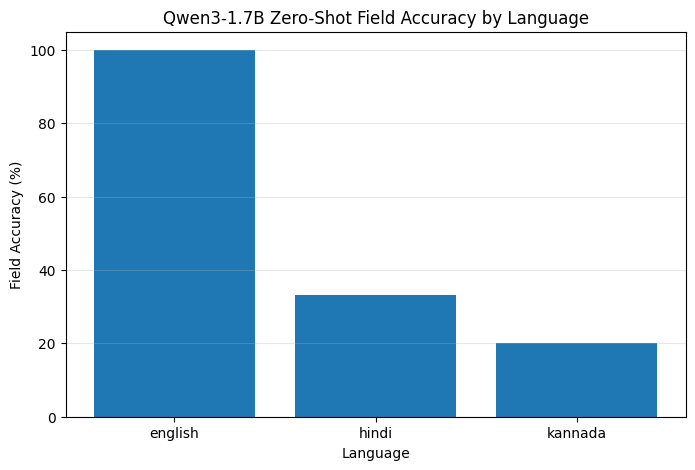

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    language_summary["language"],
    language_summary["field_accuracy"] * 100
)

plt.title("Qwen3-1.7B Zero-Shot Field Accuracy by Language")
plt.xlabel("Language")
plt.ylabel("Field Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    METRICS_DIR / "zero_shot_language_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
!apt-get update -qq
!apt-get install -y -qq fonts-noto-core

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-noto-mono.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-noto-mono_20201225-2_all.deb ...
Unpacking fonts-noto-mono (20201225-2) ...
Selecting previously unselected package fonts-noto-core.
Preparing to unpack .../fonts-noto-core_20201225-2_all.deb ...
Unpacking fonts-noto-core (20201225-2) ...
Setting up fonts-noto-mono (20201225-2) ...
Setting up fonts-noto-core (20201225-2) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [14]:
from pathlib import Path

FONT_ROOT = Path("/usr/share/fonts")

for pattern in [
    "**/NotoSans-Regular.ttf",
    "**/NotoSansDevanagari-Regular.ttf",
    "**/NotoSansKannada-Regular.ttf"
]:
    matches = list(FONT_ROOT.glob(pattern))
    print(pattern, ":", matches[:3])

**/NotoSans-Regular.ttf : [PosixPath('/usr/share/fonts/truetype/noto/NotoSans-Regular.ttf')]
**/NotoSansDevanagari-Regular.ttf : [PosixPath('/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf')]
**/NotoSansKannada-Regular.ttf : [PosixPath('/usr/share/fonts/truetype/noto/NotoSansKannada-Regular.ttf')]


In [27]:
# ============================================================
# BHARATDOC AI
# PHASE 1: MULTILINGUAL SYNTHETIC DOCUMENT GENERATOR
# ============================================================

import json
import random
import csv
import unicodedata

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)

PROJECT_ROOT = Path("/content/drive/MyDrive/BharatDocAI")

DATA_ROOT = PROJECT_ROOT / "data"

RAW_DIR = DATA_ROOT / "raw_documents"
ANNOTATION_DIR = DATA_ROOT / "annotations"
SPLIT_DIR = DATA_ROOT / "splits"

for folder in [RAW_DIR, ANNOTATION_DIR, SPLIT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_WIDTH = 1200
IMAGE_HEIGHT = 850

# ------------------------------------------------------------
# 2. FONT DISCOVERY
# ------------------------------------------------------------

def find_font(pattern):

    matches = list(
        Path("/usr/share/fonts").glob(pattern)
    )

    if not matches:
        raise FileNotFoundError(
            f"Font not found: {pattern}. "
            "Install fonts-noto-core and rerun."
        )

    return str(matches[0])


FONT_PATHS = {
    "english": find_font("**/NotoSans-Regular.ttf"),
    "hindi": find_font("**/NotoSansDevanagari-Regular.ttf"),
    "kannada": find_font("**/NotoSansKannada-Regular.ttf")
}


def get_font(language, size):

    return ImageFont.truetype(
        FONT_PATHS[language],
        size
    )


# Latin identifiers need an English font even inside
# Hindi and Kannada documents.

LATIN_FONT = get_font("english", 27)


# ------------------------------------------------------------
# 3. MULTILINGUAL DOCUMENT LABELS
# ------------------------------------------------------------

LABELS = {

    "english": {

        "invoice": {
            "title": "INVOICE",
            "name": "Customer Name",
            "date": "Invoice Date",
            "document_id": "Invoice Number",
            "address": "Address",
            "amount": "Total Amount"
        },

        "application": {
            "title": "APPLICATION FORM",
            "name": "Applicant Name",
            "date": "Application Date",
            "document_id": "Application ID",
            "address": "Address",
            "phone": "Phone Number"
        },

        "certificate": {
            "title": "CERTIFICATE",
            "name": "Recipient Name",
            "date": "Issue Date",
            "document_id": "Certificate Number",
            "institution": "Institution",
            "grade": "Grade"
        }
    },


    "hindi": {

        "invoice": {
            "title": "चालान",
            "name": "ग्राहक का नाम",
            "date": "चालान दिनांक",
            "document_id": "चालान संख्या",
            "address": "पता",
            "amount": "कुल राशि"
        },

        "application": {
            "title": "आवेदन पत्र",
            "name": "आवेदक का नाम",
            "date": "आवेदन दिनांक",
            "document_id": "आवेदन संख्या",
            "address": "पता",
            "phone": "फोन नंबर"
        },

        "certificate": {
            "title": "प्रमाण पत्र",
            "name": "प्राप्तकर्ता का नाम",
            "date": "जारी करने की तारीख",
            "document_id": "प्रमाण पत्र संख्या",
            "institution": "संस्थान",
            "grade": "श्रेणी"
        }
    },


    "kannada": {

        "invoice": {
            "title": "ಸರಕುಪಟ್ಟಿ",
            "name": "ಗ್ರಾಹಕರ ಹೆಸರು",
            "date": "ಸರಕುಪಟ್ಟಿ ದಿನಾಂಕ",
            "document_id": "ಸರಕುಪಟ್ಟಿ ಸಂಖ್ಯೆ",
            "address": "ವಿಳಾಸ",
            "amount": "ಒಟ್ಟು ಮೊತ್ತ"
        },

        "application": {
            "title": "ಅರ್ಜಿ ನಮೂನೆ",
            "name": "ಅರ್ಜಿದಾರರ ಹೆಸರು",
            "date": "ಅರ್ಜಿ ದಿನಾಂಕ",
            "document_id": "ಅರ್ಜಿ ಸಂಖ್ಯೆ",
            "address": "ವಿಳಾಸ",
            "phone": "ದೂರವಾಣಿ ಸಂಖ್ಯೆ"
        },

        "certificate": {
            "title": "ಪ್ರಮಾಣಪತ್ರ",
            "name": "ಸ್ವೀಕರಿಸುವವರ ಹೆಸರು",
            "date": "ನೀಡಿದ ದಿನಾಂಕ",
            "document_id": "ಪ್ರಮಾಣಪತ್ರ ಸಂಖ್ಯೆ",
            "institution": "ಸಂಸ್ಥೆ",
            "grade": "ಶ್ರೇಣಿ"
        }
    }
}


# ------------------------------------------------------------
# 4. SYNTHETIC DATA VALUES
# ------------------------------------------------------------

NAMES = {

    "english": [
        "Ravi Kumar",
        "Ananya Sharma",
        "Arjun Rao",
        "Priya Nair",
        "Kiran Patel",
        "Meera Joshi",
        "Rahul Verma",
        "Sneha Reddy",
        "Vikram Singh",
        "Divya Menon"
    ],

    "hindi": [
        "रवि कुमार",
        "अनन्या शर्मा",
        "अर्जुन राव",
        "प्रिया नायर",
        "किरण पटेल",
        "मीरा जोशी",
        "राहुल वर्मा",
        "स्नेहा रेड्डी",
        "विक्रम सिंह",
        "दिव्या मेनन"
    ],

    "kannada": [
        "ರವಿ ಕುಮಾರ್",
        "ಅನನ್ಯಾ ಶರ್ಮಾ",
        "ಅರ್ಜುನ್ ರಾವ್",
        "ಪ್ರಿಯಾ ನಾಯರ್",
        "ಕಿರಣ್ ಪಟೇಲ್",
        "ಮೀರಾ ಜೋಶಿ",
        "ರಾಹುಲ್ ವರ್ಮಾ",
        "ಸ್ನೇಹಾ ರೆಡ್ಡಿ",
        "ವಿಕ್ರಮ್ ಸಿಂಗ್",
        "ದಿವ್ಯಾ ಮೆನನ್"
    ]
}


ADDRESSES = {

    "english": [
        "Bengaluru",
        "Mysuru",
        "Mangaluru",
        "Hubballi",
        "Belagavi",
        "Shivamogga",
        "Tumakuru",
        "Udupi",
        "Hassan",
        "Ballari"
    ],

    "hindi": [
        "बेंगलुरु",
        "मैसूर",
        "मंगलुरु",
        "हुबली",
        "बेलगावी",
        "शिवमोग्गा",
        "तुमकुरु",
        "उडुपी",
        "हासन",
        "बल्लारी"
    ],

    "kannada": [
        "ಬೆಂಗಳೂರು",
        "ಮೈಸೂರು",
        "ಮಂಗಳೂರು",
        "ಹುಬ್ಬಳ್ಳಿ",
        "ಬೆಳಗಾವಿ",
        "ಶಿವಮೊಗ್ಗ",
        "ತುಮಕೂರು",
        "ಉಡುಪಿ",
        "ಹಾಸನ",
        "ಬಳ್ಳಾರಿ"
    ]
}


INSTITUTIONS = {

    "english": [
        "National Institute of Technology",
        "Government Science College",
        "Karnataka Technical University",
        "City Education Board"
    ],

    "hindi": [
        "राष्ट्रीय प्रौद्योगिकी संस्थान",
        "सरकारी विज्ञान महाविद्यालय",
        "कर्नाटक तकनीकी विश्वविद्यालय",
        "शहर शिक्षा बोर्ड"
    ],

    "kannada": [
        "ರಾಷ್ಟ್ರೀಯ ತಂತ್ರಜ್ಞಾನ ಸಂಸ್ಥೆ",
        "ಸರ್ಕಾರಿ ವಿಜ್ಞಾನ ಕಾಲೇಜು",
        "ಕರ್ನಾಟಕ ತಾಂತ್ರಿಕ ವಿಶ್ವವಿದ್ಯಾಲಯ",
        "ನಗರ ಶಿಕ್ಷಣ ಮಂಡಳಿ"
    ]
}


GRADES = [
    "A",
    "A+",
    "B+",
    "B",
    "Distinction"
]


DATES = [
    "12/08/2026",
    "15/09/2026",
    "21/10/2026",
    "05/07/2026",
    "18/11/2026",
    "23/06/2026",
    "09/12/2026",
    "14/04/2026",
    "27/05/2026",
    "30/03/2026"
]


# ------------------------------------------------------------
# 5. GENERATE DOCUMENT FIELDS
# ------------------------------------------------------------

def make_document_fields(language, category, index):

    serial = index + 1

    name = NAMES[language][index % len(NAMES[language])]

    address = ADDRESSES[language][
        index % len(ADDRESSES[language])
    ]

    date = DATES[index % len(DATES)]

    if category == "invoice":

        return {
            "name": name,
            "date": date,
            "document_id": f"INV-{2600 + serial}",
            "address": address,
            "amount": str(1500 + serial * 275)
        }


    elif category == "application":

        return {
            "name": name,
            "date": date,
            "document_id": f"APP-{3600 + serial}",
            "address": address,
            "phone": str(9000000000 + serial * 137)
        }


    elif category == "certificate":

        return {
            "name": name,
            "date": date,
            "document_id": f"CERT-{4600 + serial}",
            "institution": INSTITUTIONS[language][index % 4],
            "grade": GRADES[index % len(GRADES)]
        }


    else:

        raise ValueError(
            f"Unknown category: {category}"
        )


# ------------------------------------------------------------
# 6. HELPER: SELECT FONT FOR EACH VALUE
# ------------------------------------------------------------

def select_value_font(value, language, size=27):

    # If a value contains Latin letters, use Latin font.
    # This fixes INV-2601 appearing as square boxes
    # in Hindi and Kannada documents.

    contains_latin = any(
        char.isascii() and char.isalpha()
        for char in str(value)
    )

    if contains_latin:
        return get_font("english", size)

    return get_font(language, size)


# ------------------------------------------------------------
# 7. DOCUMENT RENDERING
# ------------------------------------------------------------

def draw_document(language, category, fields, template_id):

    image = Image.new(
        "RGB",
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        "white"
    )

    draw = ImageDraw.Draw(image)

    labels = LABELS[language][category]

    title_font = get_font(language, 42)

    label_font = get_font(language, 27)

    small_font = get_font(language, 19)


    # ---------------- HEADER DESIGNS ----------------

    if template_id in ["T1", "T4"]:

        draw.rectangle(
            [35, 30, 1165, 145],
            outline="black",
            width=3
        )

        draw.text(
            (60, 55),
            labels["title"],
            font=title_font,
            fill="black"
        )


    elif template_id == "T2":

        draw.text(
            (70, 45),
            labels["title"],
            font=title_font,
            fill="black"
        )

        draw.line(
            (60, 120, 1140, 120),
            fill="black",
            width=4
        )


    elif template_id == "T3":

        draw.rectangle(
            [60, 35, 1140, 130],
            fill="#E8E8E8",
            outline="black",
            width=2
        )

        draw.text(
            (85, 55),
            labels["title"],
            font=title_font,
            fill="black"
        )


    elif template_id == "T5":

        draw.text(
            (IMAGE_WIDTH // 2, 65),
            labels["title"],
            font=title_font,
            fill="black",
            anchor="mm"
        )

        draw.line(
            (100, 125, 1100, 125),
            fill="black",
            width=2
        )


    elif template_id == "T6":

        draw.rectangle(
            [50, 35, 1150, 155],
            outline="black",
            width=4
        )

        draw.text(
            (85, 70),
            labels["title"],
            font=title_font,
            fill="black"
        )

        draw.text(
            (85, 130),
            "DOCUMENT RECORD",
            font=small_font,
            fill="black"
        )


    # ---------------- FIELD RENDERING ----------------

    keys = list(fields.keys())

    start_y = 190

    for row, key in enumerate(keys):

        label = labels[key]

        value = fields[key]

        value_font = select_value_font(
            value,
            language,
            size=27
        )


        if template_id == "T1":

            y = start_y + row * 112

            draw.text(
                (85, y),
                label + ":",
                font=label_font,
                fill="black"
            )

            draw.text(
                (430, y),
                value,
                font=value_font,
                fill="black"
            )

            draw.line(
                (75, y + 65, 1120, y + 65),
                fill="#AAAAAA",
                width=1
            )


        elif template_id == "T2":

            y = start_y + row * 112

            draw.rectangle(
                [70, y - 8, 1130, y + 75],
                outline="black",
                width=1
            )

            draw.text(
                (90, y + 8),
                label,
                font=label_font,
                fill="black"
            )

            draw.text(
                (610, y + 8),
                value,
                font=value_font,
                fill="black"
            )


        elif template_id == "T3":

            y = start_y + row * 112

            draw.text(
                (85, y),
                label,
                font=label_font,
                fill="black"
            )

            draw.text(
                (85, y + 45),
                value,
                font=value_font,
                fill="black"
            )


        elif template_id == "T4":

            y = start_y + row * 112

            draw.text(
                (85, y),
                f"{row + 1}.",
                font=label_font,
                fill="black"
            )

            draw.text(
                (145, y),
                label + ":",
                font=label_font,
                fill="black"
            )

            draw.text(
                (600, y),
                value,
                font=value_font,
                fill="black"
            )


        elif template_id == "T5":

            y = start_y + row * 112

            draw.text(
                (100, y),
                label,
                font=label_font,
                fill="black"
            )

            draw.text(
                (500, y),
                ":",
                font=label_font,
                fill="black"
            )

            draw.text(
                (550, y),
                value,
                font=value_font,
                fill="black"
            )


        elif template_id == "T6":

            y = start_y + row * 112

            draw.rectangle(
                [80, y - 5, 1120, y + 78],
                outline="black",
                width=2
            )

            draw.text(
                (105, y + 8),
                label,
                font=label_font,
                fill="black"
            )

            draw.text(
                (620, y + 8),
                value,
                font=value_font,
                fill="black"
            )


    # No template identifier is printed on the document.
    # Template metadata is stored separately.

    return image


# ------------------------------------------------------------
# 8. TEMPLATE SPLIT CONFIGURATION
# ------------------------------------------------------------

SPLIT_TEMPLATES = {

    "train": {
        "T1": 2,
        "T2": 2,
        "T3": 1,
        "T4": 1
    },

    "validation": {
        "T5": 2
    },

    "test": {
        "T6": 2
    }
}


# ------------------------------------------------------------
# 9. GENERATE ALL DOCUMENTS
# ------------------------------------------------------------

records = []

document_counter = 0


for language in ["english", "hindi", "kannada"]:

    for category in [
        "invoice",
        "application",
        "certificate"
    ]:

        category_index = 0

        for split, templates in SPLIT_TEMPLATES.items():

            for template_id, count in templates.items():

                for _ in range(count):

                    fields = make_document_fields(
                        language,
                        category,
                        category_index
                    )

                    document_counter += 1

                    doc_id = (
                        f"{language}_{category}_"
                        f"{document_counter:03d}"
                    )

                    image = draw_document(
                        language,
                        category,
                        fields,
                        template_id
                    )

                    image_path = (
                        RAW_DIR / f"{doc_id}.png"
                    )

                    image.save(image_path)


                    # Build ground-truth text

                    labels = LABELS[language][category]

                    text_lines = [
                        labels["title"]
                    ]

                    for key, value in fields.items():

                        text_lines.append(
                            f"{labels[key]}: {value}"
                        )


                    record = {

                        "document_id": doc_id,

                        "language": language,

                        "category": category,

                        "template_family": template_id,

                        "split": split,

                        "image_path": str(image_path),

                        "ground_truth": fields,

                        "document_text": "\n".join(text_lines)
                    }

                    records.append(record)

                    category_index += 1


# ------------------------------------------------------------
# 10. SAVE STRUCTURED ANNOTATIONS
# ------------------------------------------------------------

jsonl_path = (
    ANNOTATION_DIR / "synthetic_documents.jsonl"
)

with open(
    jsonl_path,
    "w",
    encoding="utf-8"
) as f:

    for record in records:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )


# ------------------------------------------------------------
# 11. SAVE DATASET MANIFEST
# ------------------------------------------------------------

manifest_path = (
    SPLIT_DIR / "dataset_manifest.csv"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "document_id",
            "language",
            "category",
            "template_family",
            "split",
            "image_path"
        ]
    )

    writer.writeheader()

    for record in records:

        writer.writerow({

            key: record[key]

            for key in writer.fieldnames

        })


# ------------------------------------------------------------
# 12. SAVE SPLIT-SPECIFIC JSONL FILES
# ------------------------------------------------------------

for split in ["train", "validation", "test"]:

    split_records = [
        record
        for record in records
        if record["split"] == split
    ]

    split_path = (
        SPLIT_DIR / f"{split}.jsonl"
    )

    with open(
        split_path,
        "w",
        encoding="utf-8"
    ) as f:

        for record in split_records:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )


# ------------------------------------------------------------
# 13. FINAL GENERATION SUMMARY
# ------------------------------------------------------------

print("=" * 60)
print("BHARATDOC AI DATASET GENERATION COMPLETED")
print("=" * 60)

print("Total documents:", len(records))

print("Languages:", 3)

print("Document categories:", 3)

print("Template families:", 6)

print("\nSaved files:")

print("Annotations:", jsonl_path)

print("Manifest:", manifest_path)

print("Split directory:", SPLIT_DIR)

print("\nDataset split counts:")

for split in ["train", "validation", "test"]:

    count = sum(
        1 for record in records
        if record["split"] == split
    )

    print(f"{split}: {count}")

print("=" * 60)

BHARATDOC AI DATASET GENERATION COMPLETED
Total documents: 90
Languages: 3
Document categories: 3
Template families: 6

Saved files:
Annotations: /content/drive/MyDrive/BharatDocAI/data/annotations/synthetic_documents.jsonl
Manifest: /content/drive/MyDrive/BharatDocAI/data/splits/dataset_manifest.csv
Split directory: /content/drive/MyDrive/BharatDocAI/data/splits

Dataset split counts:
train: 54
validation: 18
test: 18


In [30]:
# ============================================================
# DATASET VALIDATION
# ============================================================

manifest_df = pd.read_csv(manifest_path)

print("TOTAL DOCUMENTS:", len(manifest_df))

print("\nLANGUAGE DISTRIBUTION")

display(
    manifest_df["language"].value_counts()
)

print("\nCATEGORY DISTRIBUTION")

display(
    manifest_df["category"].value_counts()
)

print("\nSPLIT DISTRIBUTION")

display(
    manifest_df["split"].value_counts()
)

print("\nLANGUAGE-WISE SPLIT")

display(
    pd.crosstab(
        manifest_df["language"],
        manifest_df["split"]
    )
)

print("\nCATEGORY-WISE SPLIT")

display(
    pd.crosstab(
        manifest_df["category"],
        manifest_df["split"]
    )
)

# ------------------------------------------------------------
# VALIDATION CHECKS
# ------------------------------------------------------------

assert len(manifest_df) == 90

assert manifest_df["document_id"].is_unique

assert manifest_df["language"].value_counts().to_dict() == {
    "english": 30,
    "hindi": 30,
    "kannada": 30
}

assert manifest_df["category"].value_counts().to_dict() == {
    "invoice": 30,
    "application": 30,
    "certificate": 30
}

assert manifest_df["split"].value_counts().to_dict() == {
    "train": 54,
    "validation": 18,
    "test": 18
}

# Check that no template family crosses splits
template_splits = (
    manifest_df.groupby("template_family")["split"].nunique()
)

assert template_splits.max() == 1

# Check all images exist
assert all(
    Path(path).exists()
    for path in manifest_df["image_path"]
)

print("\nALL DATASET VALIDATION CHECKS PASSED!")

TOTAL DOCUMENTS: 90

LANGUAGE DISTRIBUTION


,count
language,
english,30
hindi,30
kannada,30



CATEGORY DISTRIBUTION


,count
category,
invoice,30
application,30
certificate,30



SPLIT DISTRIBUTION


,count
split,
train,54
validation,18
test,18



LANGUAGE-WISE SPLIT


split,test,train,validation
language,,,
english,6,18,6
hindi,6,18,6
kannada,6,18,6



CATEGORY-WISE SPLIT


split,test,train,validation
category,,,
application,6,18,6
certificate,6,18,6
invoice,6,18,6



ALL DATASET VALIDATION CHECKS PASSED!


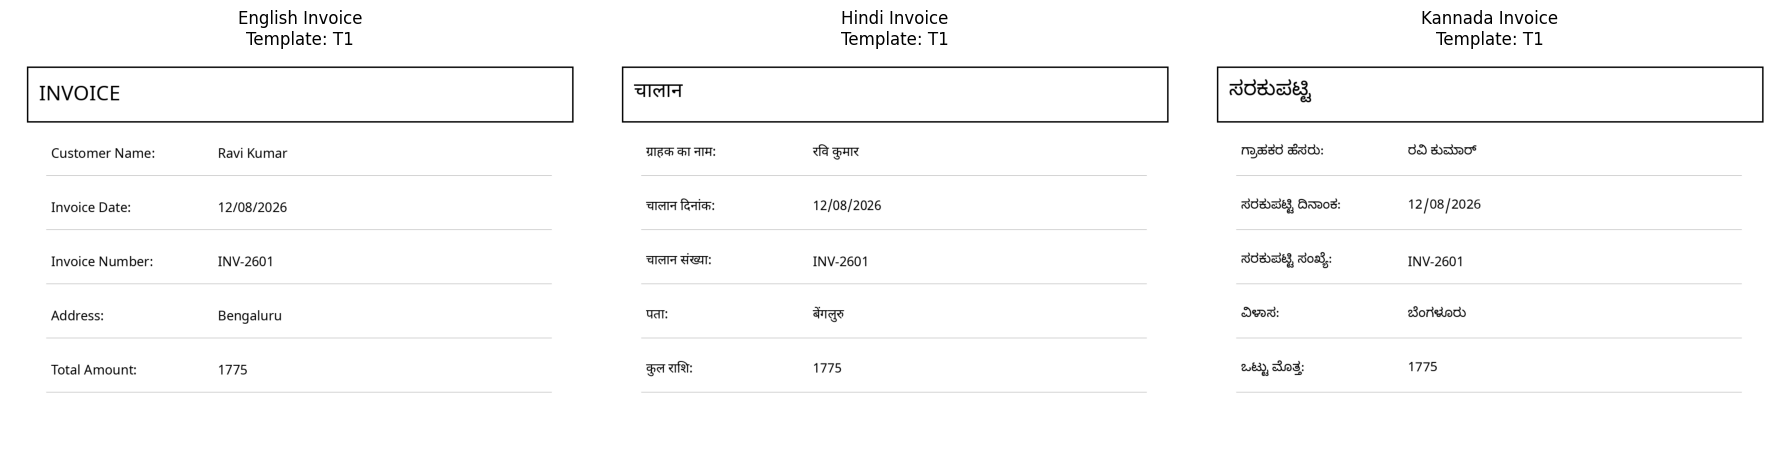

In [32]:
# ============================================================
# VISUAL INSPECTION
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

sample_records = []

for language in ["english", "hindi", "kannada"]:

    sample = next(
        record for record in records

        if record["language"] == language
        and record["category"] == "invoice"
    )

    sample_records.append(sample)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7)
)

for ax, record in zip(axes, sample_records):

    image = Image.open(record["image_path"])

    ax.imshow(image)

    ax.set_title(
        f"{record['language'].title()} Invoice\n"
        f"Template: {record['template_family']}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# BHARATDOC AI
# PHASE 1.1: DATASET INDEPENDENCE IMPROVEMENT
# ============================================================

import json
import csv
import random
import pandas as pd

from pathlib import Path
from datetime import date, timedelta

random.seed(42)

# ------------------------------------------------------------
# 1. GENERATE 30 DISTINCT SYNTHETIC NAMES PER LANGUAGE
# ------------------------------------------------------------

def create_unique_names(language, count=30):

    original_names = NAMES[language]

    first_names = list(dict.fromkeys(
        name.split()[0] for name in original_names
    ))

    surnames = list(dict.fromkeys(
        name.split()[-1] for name in original_names
    ))

    combinations = [
        f"{first} {surname}"
        for first in first_names
        for surname in surnames
        if first != surname
    ]

    random.shuffle(combinations)

    if len(combinations) < count:
        raise ValueError("Not enough unique name combinations.")

    return combinations[:count]


UNIQUE_NAMES = {
    language: create_unique_names(language, 30)
    for language in ["english", "hindi", "kannada"]
}

# ------------------------------------------------------------
# 2. REBUILD EACH DOCUMENT WITH UNIQUE VALUES
# ------------------------------------------------------------

# Unique dates across all 90 documents
date_start = date(2026, 1, 1)

# Unique global document identifier counter
global_counter = 0

# Track the index of each language
language_counters = {
    "english": 0,
    "hindi": 0,
    "kannada": 0
}

updated_records = []

for old_record in records:

    global_counter += 1

    language = old_record["language"]
    category = old_record["category"]
    template_id = old_record["template_family"]
    split = old_record["split"]

    language_index = language_counters[language]
    language_counters[language] += 1

    # Unique name for each document within its language
    name = UNIQUE_NAMES[language][language_index]

    # Unique date across the entire dataset
    document_date = (
        date_start + timedelta(days=global_counter - 1)
    ).strftime("%d/%m/%Y")

    # Reuse realistic city names.
    # Address repetition is expected for a categorical field.
    address = ADDRESSES[language][language_index % 10]

    # Unique document identifier across all languages/categories
    if category == "invoice":
        document_id = f"INV-{global_counter:04d}"

    elif category == "application":
        document_id = f"APP-{global_counter:04d}"

    elif category == "certificate":
        document_id = f"CERT-{global_counter:04d}"

    # Rebuild fields for the relevant category
    if category == "invoice":

        fields = {
            "name": name,
            "date": document_date,
            "document_id": document_id,
            "address": address,
            "amount": str(1500 + global_counter * 137)
        }

    elif category == "application":

        fields = {
            "name": name,
            "date": document_date,
            "document_id": document_id,
            "address": address,
            "phone": str(9000000000 + global_counter * 137)
        }

    elif category == "certificate":

        fields = {
            "name": name,
            "date": document_date,
            "document_id": document_id,
            "institution": INSTITUTIONS[language][
                language_index % len(INSTITUTIONS[language])
            ],
            "grade": GRADES[language_index % len(GRADES)]
        }

    # Render the updated document image
    image = draw_document(
        language,
        category,
        fields,
        template_id
    )

    doc_id = old_record["document_id"]

    image_path = RAW_DIR / f"{doc_id}.png"

    image.save(image_path)

    # Rebuild document text
    labels = LABELS[language][category]

    text_lines = [labels["title"]]

    for key, value in fields.items():
        text_lines.append(f"{labels[key]}: {value}")

    updated_record = {
        "document_id": doc_id,
        "language": language,
        "category": category,
        "template_family": template_id,
        "split": split,
        "image_path": str(image_path),
        "ground_truth": fields,
        "document_text": "\n".join(text_lines)
    }

    updated_records.append(updated_record)


# Replace previous records in memory
records = updated_records

print("Updated documents:", len(records))

# ------------------------------------------------------------
# 3. SAVE COMPLETE ANNOTATIONS
# ------------------------------------------------------------

jsonl_path = ANNOTATION_DIR / "synthetic_documents.jsonl"

with open(jsonl_path, "w", encoding="utf-8") as f:

    for record in records:
        f.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

# ------------------------------------------------------------
# 4. SAVE ALL THREE SPLITS
# ------------------------------------------------------------

for split in ["train", "validation", "test"]:

    split_records = [
        record for record in records
        if record["split"] == split
    ]

    split_path = SPLIT_DIR / f"{split}.jsonl"

    with open(split_path, "w", encoding="utf-8") as f:

        for record in split_records:
            f.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

    print(f"{split}: {len(split_records)} documents saved")


# ------------------------------------------------------------
# 5. REBUILD DATASET MANIFEST
# ------------------------------------------------------------

manifest_path = SPLIT_DIR / "dataset_manifest.csv"

manifest_fields = [
    "document_id",
    "language",
    "category",
    "template_family",
    "split",
    "image_path"
]

with open(
    manifest_path,
    "w",
    encoding="utf-8",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=manifest_fields
    )

    writer.writeheader()

    for record in records:

        writer.writerow({
            key: record[key]
            for key in manifest_fields
        })


print("\nDataset records, images and split files regenerated.")
print("Annotations:", jsonl_path)
print("Manifest:", manifest_path)

Updated documents: 90
train: 54 documents saved
validation: 18 documents saved
test: 18 documents saved

Dataset records, images and split files regenerated.
Annotations: /content/drive/MyDrive/BharatDocAI/data/annotations/synthetic_documents.jsonl
Manifest: /content/drive/MyDrive/BharatDocAI/data/splits/dataset_manifest.csv


In [34]:
# ============================================================
# DATASET INTEGRITY AND LEAKAGE AUDIT
# ============================================================

import json
import pandas as pd
from pathlib import Path

# Reload saved annotations, not just in-memory records

with open(
    ANNOTATION_DIR / "synthetic_documents.jsonl",
    "r",
    encoding="utf-8"
) as f:

    audited_records = [
        json.loads(line)
        for line in f if line.strip()
    ]

manifest_df = pd.read_csv(manifest_path)

# ------------------------------------------------------------
# 1. BASIC DATASET CHECKS
# ------------------------------------------------------------

assert len(audited_records) == 90
assert len(manifest_df) == 90

assert manifest_df["document_id"].is_unique

assert manifest_df["language"].value_counts().to_dict() == {
    "english": 30,
    "hindi": 30,
    "kannada": 30
}

assert manifest_df["category"].value_counts().to_dict() == {
    "invoice": 30,
    "application": 30,
    "certificate": 30
}

assert manifest_df["split"].value_counts().to_dict() == {
    "train": 54,
    "validation": 18,
    "test": 18
}

# ------------------------------------------------------------
# 2. TEMPLATE FAMILY SEPARATION
# ------------------------------------------------------------

template_overlap = (
    manifest_df.groupby("template_family")["split"].nunique()
)

assert template_overlap.max() == 1

# ------------------------------------------------------------
# 3. UNIQUE VALUE AUDIT
# ------------------------------------------------------------

def collect_values(records, field):

    return {
        record["ground_truth"].get(field, "")
        for record in records
        if record["ground_truth"].get(field, "")
    }


def values_by_split(records, field, split):

    return {
        record["ground_truth"].get(field, "")
        for record in records
        if record["split"] == split
        and record["ground_truth"].get(field, "")
    }


for field in ["name", "date", "document_id"]:

    train_values = values_by_split(
        audited_records, field, "train"
    )

    val_values = values_by_split(
        audited_records, field, "validation"
    )

    test_values = values_by_split(
        audited_records, field, "test"
    )

    train_val_overlap = train_values & val_values
    train_test_overlap = train_values & test_values
    val_test_overlap = val_values & test_values

    print(f"\nField: {field}")
    print("Train-validation overlap:", len(train_val_overlap))
    print("Train-test overlap:", len(train_test_overlap))
    print("Validation-test overlap:", len(val_test_overlap))

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0
    assert len(val_test_overlap) == 0


# ------------------------------------------------------------
# 4. IMAGE EXISTENCE CHECK
# ------------------------------------------------------------

missing_images = [
    record["image_path"]
    for record in audited_records
    if not Path(record["image_path"]).exists()
]

assert len(missing_images) == 0

# ------------------------------------------------------------
# 5. ANNOTATION CONSISTENCY
# ------------------------------------------------------------

for record in audited_records:

    language = record["language"]
    category = record["category"]

    expected_keys = set(
        LABELS[language][category].keys()
    ) - {"title"}

    actual_keys = set(record["ground_truth"].keys())

    assert actual_keys == expected_keys

    assert record["document_text"].startswith(
        LABELS[language][category]["title"]
    )

# ------------------------------------------------------------
# 6. SAVE AUDIT SUMMARY
# ------------------------------------------------------------

audit_summary = {
    "total_documents": len(audited_records),
    "unique_document_ids": manifest_df["document_id"].nunique(),
    "languages": manifest_df["language"].value_counts().to_dict(),
    "categories": manifest_df["category"].value_counts().to_dict(),
    "splits": manifest_df["split"].value_counts().to_dict(),
    "template_families": sorted(
        manifest_df["template_family"].unique().tolist()
    ),
    "template_leakage": False,
    "name_date_document_id_overlap": False,
    "missing_images": len(missing_images),
    "annotation_consistency": True
}

audit_path = (
    PROJECT_ROOT / "outputs/metrics/dataset_integrity_audit.json"
)

audit_path.parent.mkdir(parents=True, exist_ok=True)

with open(audit_path, "w", encoding="utf-8") as f:

    json.dump(
        audit_summary,
        f,
        ensure_ascii=False,
        indent=4
    )

print("\n" + "=" * 55)
print("DATASET INTEGRITY AUDIT PASSED")
print("=" * 55)

print(json.dumps(
    audit_summary,
    ensure_ascii=False,
    indent=4
))

print("\nAudit saved to:", audit_path)


Field: name
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Field: date
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Field: document_id
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

DATASET INTEGRITY AUDIT PASSED
{
    "total_documents": 90,
    "unique_document_ids": 90,
    "languages": {
        "english": 30,
        "hindi": 30,
        "kannada": 30
    },
    "categories": {
        "invoice": 30,
        "application": 30,
        "certificate": 30
    },
    "splits": {
        "train": 54,
        "validation": 18,
        "test": 18
    },
    "template_families": [
        "T1",
        "T2",
        "T3",
        "T4",
        "T5",
        "T6"
    ],
    "template_leakage": false,
    "name_date_document_id_overlap": false,
    "missing_images": 0,
    "annotation_consistency": true
}

Audit saved to: /content/drive/MyDrive/BharatDocAI/outputs/metrics/dataset_integrity_audit.j

In [35]:
for split in ["train", "validation", "test"]:

    path = SPLIT_DIR / f"{split}.jsonl"

    with open(path, "r", encoding="utf-8") as f:
        split_data = [
            json.loads(line)
            for line in f if line.strip()
        ]

    print(
        f"{split.upper()}: {len(split_data)} records"
    )

    print(
        "Languages:",
        pd.Series([r["language"] for r in split_data])
        .value_counts()
        .to_dict()
    )

TRAIN: 54 records
Languages: {'english': 18, 'hindi': 18, 'kannada': 18}
VALIDATION: 18 records
Languages: {'english': 6, 'hindi': 6, 'kannada': 6}
TEST: 18 records
Languages: {'english': 6, 'hindi': 6, 'kannada': 6}


In [36]:
# ============================================================
# BHARATDOC AI
# PHASE 1.2: CONTROLLED IMAGE DEGRADATION
# ============================================================

import json
import cv2
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/BharatDocAI")

ANNOTATION_PATH = (
    PROJECT_ROOT / "data/annotations/synthetic_documents.jsonl"
)

RAW_DIR = PROJECT_ROOT / "data/raw_documents"

DEGRADED_DIR = PROJECT_ROOT / "data/processed/degraded"

DEGRADED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD THE DATASET
# ------------------------------------------------------------

with open(ANNOTATION_PATH, "r", encoding="utf-8") as f:

    records = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

print("Loaded documents:", len(records))

assert len(records) == 90

# ------------------------------------------------------------
# 3. DEFINE DEGRADATION LEVELS
# ------------------------------------------------------------

DEGRADATION_CONFIG = {

    "gaussian_blur": {
        "mild": 3,
        "moderate": 5,
        "severe": 7
    },

    "gaussian_noise": {
        "mild": 10,
        "moderate": 25,
        "severe": 40
    },

    "rotation": {
        "mild": 1.0,
        "moderate": 2.5,
        "severe": 4.0
    },

    "low_contrast": {
        "mild": 0.8,
        "moderate": 0.6,
        "severe": 0.4
    },

    "jpeg_compression": {
        "mild": 60,
        "moderate": 35,
        "severe": 15
    }
}

# ------------------------------------------------------------
# 4. REPRODUCIBLE RANDOM SEED
# ------------------------------------------------------------

def stable_seed(document_id, corruption, severity):

    key = f"{document_id}_{corruption}_{severity}"

    digest = hashlib.sha256(
        key.encode("utf-8")
    ).hexdigest()

    return int(digest[:8], 16)


# ------------------------------------------------------------
# 5. DEGRADATION FUNCTIONS
# ------------------------------------------------------------

def apply_blur(image, kernel_size):

    return cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        0
    )


def apply_noise(image, sigma, seed):

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        0,
        sigma,
        image.shape
    )

    noisy = image.astype(np.float32) + noise

    return np.clip(
        noisy,
        0,
        255
    ).astype(np.uint8)


def apply_rotation(image, angle):

    height, width = image.shape[:2]

    center = (width / 2, height / 2)

    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    return cv2.warpAffine(
        image,
        matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255, 255, 255)
    )


def apply_low_contrast(image, alpha):

    # Keep the midpoint near 127.5 while reducing contrast

    beta = 127.5 * (1 - alpha)

    result = (
        image.astype(np.float32) * alpha
        + beta
    )

    return np.clip(
        result,
        0,
        255
    ).astype(np.uint8)


def apply_jpeg_compression(image, quality):

    encode_params = [
        cv2.IMWRITE_JPEG_QUALITY,
        quality
    ]

    success, encoded = cv2.imencode(
        ".jpg",
        image,
        encode_params
    )

    if not success:
        raise RuntimeError("JPEG encoding failed")

    decoded = cv2.imdecode(
        encoded,
        cv2.IMREAD_COLOR
    )

    return decoded


# ------------------------------------------------------------
# 6. UNIFIED DEGRADATION FUNCTION
# ------------------------------------------------------------

def degrade_image(
    image,
    corruption,
    severity,
    parameter,
    seed
):

    if corruption == "gaussian_blur":

        return apply_blur(image, parameter)

    elif corruption == "gaussian_noise":

        return apply_noise(image, parameter, seed)

    elif corruption == "rotation":

        return apply_rotation(image, parameter)

    elif corruption == "low_contrast":

        return apply_low_contrast(image, parameter)

    elif corruption == "jpeg_compression":

        return apply_jpeg_compression(image, parameter)

    else:

        raise ValueError(
            f"Unknown corruption: {corruption}"
        )


# ------------------------------------------------------------
# 7. GENERATE ALL DEGRADED IMAGES
# ------------------------------------------------------------

metadata = []

failed_images = []

for record in tqdm(records, desc="Processing documents"):

    document_id = record["document_id"]

    split = record["split"]

    language = record["language"]

    category = record["category"]

    original_path = Path(record["image_path"])

    if not original_path.exists():

        failed_images.append(document_id)

        continue

    original = cv2.imread(str(original_path))

    if original is None:

        failed_images.append(document_id)

        continue

    # Save a clean reference entry.
    # The original image remains in raw_documents.

    metadata.append({

        "document_id": document_id,
        "language": language,
        "category": category,
        "template_family": record["template_family"],
        "split": split,
        "corruption": "clean",
        "severity": "none",
        "parameter": 0,
        "image_path": str(original_path)

    })

    # Generate all 15 degradation variants

    for corruption, severity_levels in DEGRADATION_CONFIG.items():

        for severity, parameter in severity_levels.items():

            seed = stable_seed(
                document_id,
                corruption,
                severity
            )

            degraded = degrade_image(
                original,
                corruption,
                severity,
                parameter,
                seed
            )

            output_dir = (
                DEGRADED_DIR
                / split
                / document_id
            )

            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            output_name = (
                f"{document_id}_"
                f"{corruption}_"
                f"{severity}.png"
            )

            output_path = output_dir / output_name

            success = cv2.imwrite(
                str(output_path),
                degraded
            )

            if not success:

                failed_images.append(
                    str(output_path)
                )

                continue

            metadata.append({

                "document_id": document_id,
                "language": language,
                "category": category,
                "template_family": record["template_family"],
                "split": split,
                "corruption": corruption,
                "severity": severity,
                "parameter": parameter,
                "image_path": str(output_path)

            })


# ------------------------------------------------------------
# 8. SAVE DEGRADATION MANIFEST
# ------------------------------------------------------------

degradation_df = pd.DataFrame(metadata)

manifest_output = (
    PROJECT_ROOT
    / "data/processed/degradation_manifest.csv"
)

degradation_df.to_csv(
    manifest_output,
    index=False,
    encoding="utf-8"
)

print("\nDegradation generation completed.")

print("Total records:", len(degradation_df))

print("Failed images:", len(failed_images))

print("Manifest:", manifest_output)

if failed_images:

    print("\nFailed image paths:")

    for path in failed_images[:10]:
        print(path)

Loaded documents: 90


Processing documents:   0%|          | 0/90 [00:00<?, ?it/s]


Degradation generation completed.
Total records: 1440
Failed images: 0
Manifest: /content/drive/MyDrive/BharatDocAI/data/processed/degradation_manifest.csv


In [37]:
# ============================================================
# PHASE 1.2: DEGRADATION VALIDATION
# ============================================================

import cv2
import pandas as pd

manifest_path = (
    PROJECT_ROOT
    / "data/processed/degradation_manifest.csv"
)

df = pd.read_csv(manifest_path)

# ------------------------------------------------------------
# 1. EXPECTED COUNTS
# ------------------------------------------------------------

print("Total image records:", len(df))

assert len(df) == 1440

assert (df["corruption"] == "clean").sum() == 90

assert (df["corruption"] != "clean").sum() == 1350

# ------------------------------------------------------------
# 2. CORRUPTION COUNTS
# ------------------------------------------------------------

print("\nCorruption counts:")

print(
    df["corruption"].value_counts()
)

# ------------------------------------------------------------
# 3. SEVERITY COUNTS
# ------------------------------------------------------------

print("\nSeverity counts:")

print(
    df["severity"].value_counts()
)

# ------------------------------------------------------------
# 4. SPLIT COUNTS
# ------------------------------------------------------------

print("\nSplit counts:")

print(
    df.groupby(["split", "corruption"]).size()
)

# ------------------------------------------------------------
# 5. FILE EXISTENCE
# ------------------------------------------------------------

missing = [
    path
    for path in df["image_path"]
    if not Path(path).exists()
]

assert len(missing) == 0

# ------------------------------------------------------------
# 6. IMAGE READABILITY
# ------------------------------------------------------------

unreadable = []

for path in tqdm(
    df["image_path"],
    desc="Checking image readability"
):

    image = cv2.imread(path)

    if image is None:
        unreadable.append(path)

assert len(unreadable) == 0

# ------------------------------------------------------------
# 7. DOCUMENT AND CORRUPTION UNIQUENESS
# ------------------------------------------------------------

assert not df.duplicated(
    subset=[
        "document_id",
        "corruption",
        "severity"
    ]
).any()

print("\n" + "=" * 50)
print("IMAGE DEGRADATION VALIDATION PASSED")
print("=" * 50)

print("Clean images:", 90)
print("Degraded images:", 1350)
print("Total images:", len(df))
print("Missing images:", len(missing))
print("Unreadable images:", len(unreadable))

Total image records: 1440

Corruption counts:
corruption
gaussian_blur       270
gaussian_noise      270
low_contrast        270
rotation            270
jpeg_compression    270
clean                90
Name: count, dtype: int64

Severity counts:
severity
mild        450
moderate    450
severe      450
none         90
Name: count, dtype: int64

Split counts:
split       corruption      
test        clean                18
            gaussian_blur        54
            gaussian_noise       54
            jpeg_compression     54
            low_contrast         54
            rotation             54
train       clean                54
            gaussian_blur       162
            gaussian_noise      162
            jpeg_compression    162
            low_contrast        162
            rotation            162
validation  clean                18
            gaussian_blur        54
            gaussian_noise       54
            jpeg_compression     54
            low_contrast         54


Checking image readability:   0%|          | 0/1440 [00:00<?, ?it/s]


IMAGE DEGRADATION VALIDATION PASSED
Clean images: 90
Degraded images: 1350
Total images: 1440
Missing images: 0
Unreadable images: 0


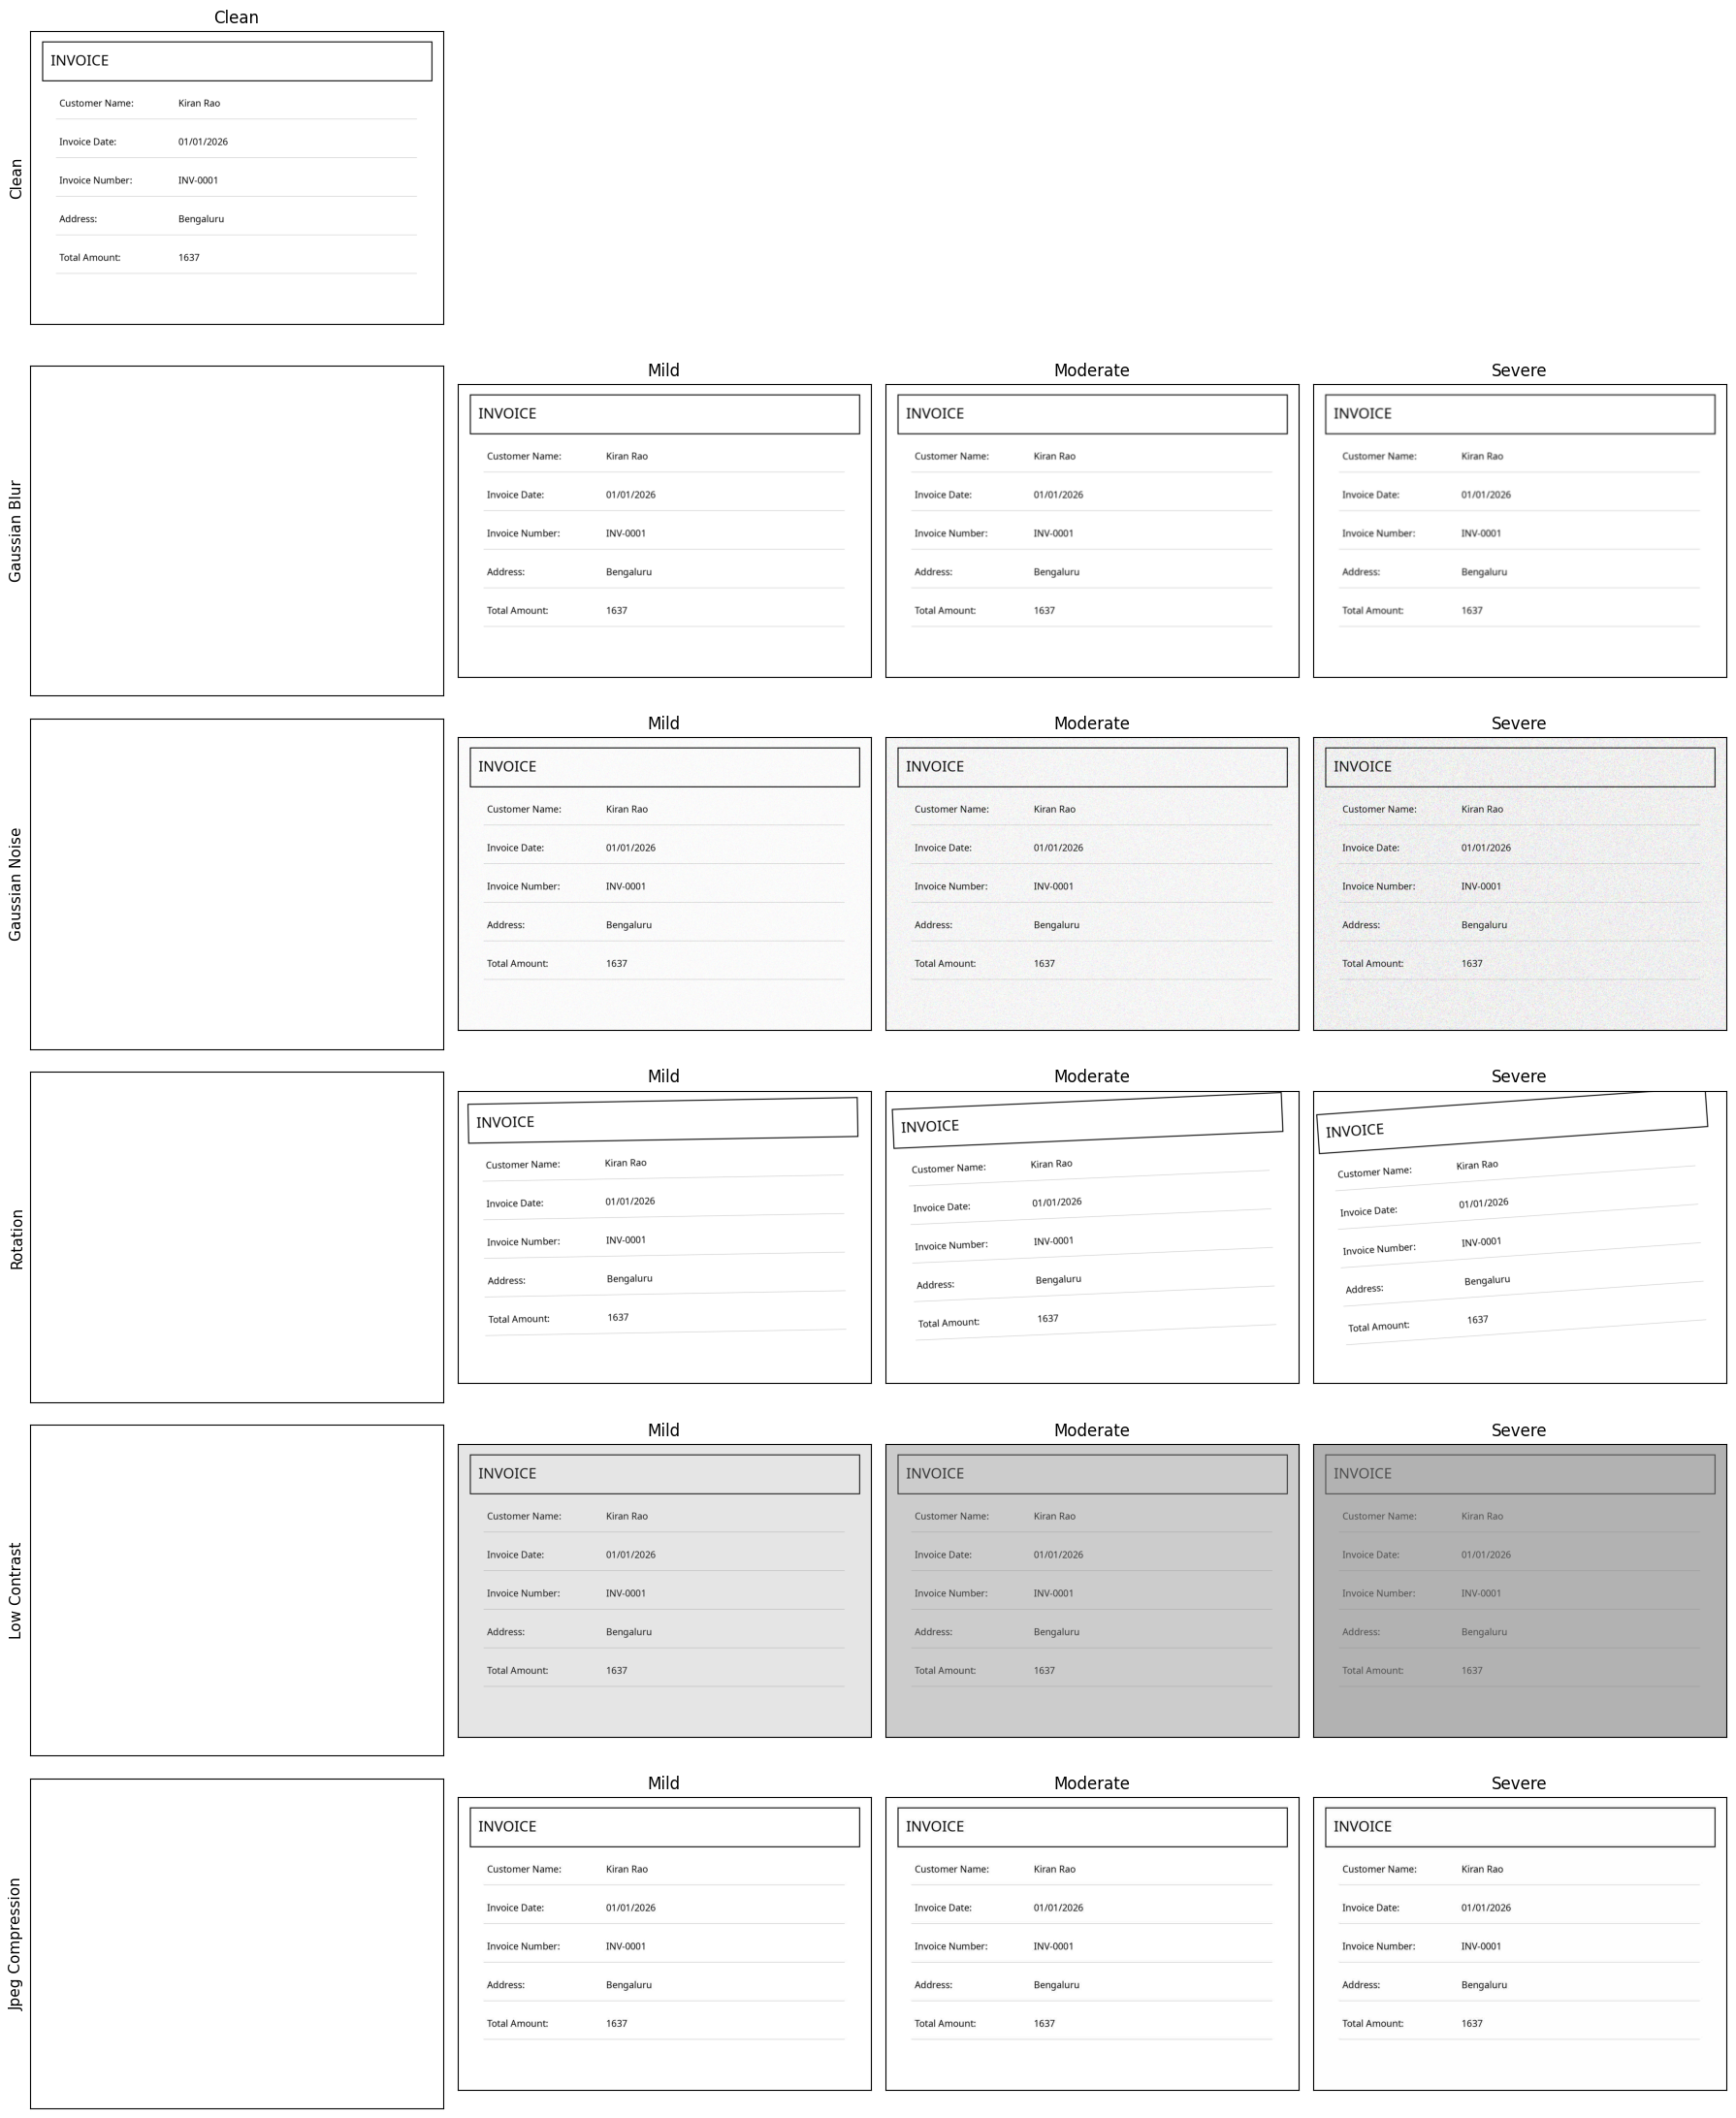

In [38]:
import matplotlib.pyplot as plt
from PIL import Image

sample_id = "english_invoice_001"

sample_df = df[
    (df["document_id"] == sample_id)
]

corruptions = [
    "clean",
    "gaussian_blur",
    "gaussian_noise",
    "rotation",
    "low_contrast",
    "jpeg_compression"
]

fig, axes = plt.subplots(
    len(corruptions),
    4,
    figsize=(18, 22)
)

for row, corruption in enumerate(corruptions):

    if corruption == "clean":

        entry = sample_df[
            sample_df["corruption"] == "clean"
        ].iloc[0]

        image = Image.open(entry["image_path"])

        axes[row, 0].imshow(image)
        axes[row, 0].set_title("Clean")

        for col in [1, 2, 3]:
            axes[row, col].axis("off")

    else:

        for col, severity in enumerate(
            ["mild", "moderate", "severe"]
        ):

            entry = sample_df[
                (sample_df["corruption"] == corruption)
                & (sample_df["severity"] == severity)
            ].iloc[0]

            image = Image.open(entry["image_path"])

            axes[row, col + 1].imshow(image)

            axes[row, col + 1].set_title(
                severity.title()
            )

    axes[row, 0].set_ylabel(
        corruption.replace("_", " ").title(),
        fontsize=11
    )

    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()

plt.show()